# StomataSeg: Semi-Supervised Instance Segmentation for Sorghum Stomatal Components — evaluation reproduction

Reproduces the **evaluation** of the released StomataSeg retrained Mask R-CNN
(ConvNeXt-V2-Base) on the official **StomataSeg test split** (1,160 patches; classes:
pore area, guard cell area, complex area) and compares per-class AP with Table 4 of the
paper. It also visualizes reference annotations and model predictions on a few test patches.

- Paper: *StomataSeg: Semi-Supervised Instance Segmentation for Sorghum Stomatal Components* —
  Computers and Electronics in Agriculture, DOI [10.1016/j.compag.2026.112442](https://doi.org/10.1016/j.compag.2026.112442);
  preprint arXiv:2602.00703, https://arxiv.org/abs/2602.00703
- Code: https://github.com/Davidhzt/StomataSeg_full (pinned commit `6ba8a6614a0a9e0eb412958b34f0e360e0ec7a73`)
- Weights: GitHub release [v1.0.0](https://github.com/Davidhzt/StomataSeg_full/releases/tag/v1.0.0), `retrained_best.pth` (1,295,159,841 bytes, sha256 `651f8f85e043515d1d2f4a3b8119e37d16ebb737668490f2ae4e4c0f0e9cef16`)
- Dataset: Zenodo record [18216859](https://zenodo.org/records/18216859), `original_patches.zip` (383,644,997 bytes, md5 `2f7f815aeef3d06b629d185d0ccde646`)

**Scope** (partial demonstration, inference only):
- ✅ Load the authors' released retrained checkpoint and run their evaluation path (their own stored test pipeline + COCO AP) on the **full test split**
- ✅ Per-class AP / AP50 comparison with the paper's Table 4 (Overall 49.20/88.80; pore 39.10/82.90; guard cell 50.30/90.60; complex 58.30/93.10 — mask AP)
- ✅ Reference-annotation and prediction visualizations on a few test patches
- ❌ Training, the seed-model baseline, semantic baselines, the SAM2.1 baseline, and pseudo-labelling are out of scope

**Important provenance note.** The repo's standalone ConvNeXt config
(`mask_rcnn_convnext_v2_b_stomata.py`) resizes test images to 800 px and produces much
lower AP. The released checkpoint **stores its own training config** (experiment
`mask_rcnn_patched_dataset_20251019_092324`), whose test pipeline keeps patches at their
native 341 px scale; this notebook uses that stored config — with only the data paths
re-pointed — which reproduces Table 4 exactly. Table 4's "AP" is mask (segm) AP.
(Table 4 values were verified from the arXiv:2602.00703 preprint full text; the published
article's investigation independently records the same overall 49.20 AP.)

**Reproducibility note.** This notebook is adapted from a previously validated
reproduction of the arXiv preprint version in the same project; the scientific cells are
unchanged and were re-executed end to end on a fresh T4 runtime for the journal version.

**Runtime: a T4 GPU (or better) is required.** The notebook stops with a clear error on
CPU-only runtimes; the full 1,160-patch evaluation is not practical on CPU.

**Expected duration:** ≈12–20 minutes total (≈6–9 min dependency setup, ≈2–4 min dataset +
checkpoint downloads ≈1.7 GiB, ≈2–3 min evaluation on T4). Free-tier availability may differ.

日本語の概要: このノートブックは、StomataSeg（ソルガム気孔構造の半教師ありセグメンテーション、
Computers and Electronics in Agriculture, DOI 10.1016/j.compag.2026.112442、プレプリント
arXiv:2602.00703）の**評価**を再現します。著者公開の再学習済み Mask R-CNN
（ConvNeXt-V2-Base）を、チェックポイント自身が保持する評価設定（テスト分割 1,160 パッチ、
341 px ネイティブスケール）で全文評価し、論文 Table 4 のクラス別 mask AP と比較します
（本実行では完全一致）。学習・seed モデル比較・意味論的ベースライン・SAM2.1・擬似ラベル生成は対象外です。
**T4 GPU が必要です**（CPU ランタイムでは明示的なエラーで停止します）。

*This notebook was authored from the paper's released code and data; it is not an official
authors' notebook. Deviations from the authors' exact workflow are documented inline.*

## 1. Runtime check

**Select a T4 GPU runtime before running** (`ランタイム` → `ランタイムのタイプを変更` → `T4 GPU`).
This cell verifies CUDA availability and stops with a clear error on CPU-only runtimes,
because the full test-split evaluation is impractical there.

日本語: 最初に T4 GPU ランタイムを選択してください。このセルは CUDA を確認し、
CPU のみの環境では明示的なエラーで停止します。

In [ ]:
import torch
print("torch (preinstalled):", torch.__version__, "| CUDA runtime:", torch.version.cuda)
if not torch.cuda.is_available():
    raise RuntimeError(
        "No CUDA GPU detected. This notebook evaluates 1,160 test patches with a "
        "ConvNeXt-V2-Base Mask R-CNN and requires a T4 GPU runtime "
        "(Runtime > Change runtime type > T4 GPU). CPU execution is not supported for this scope."
    )
print("GPU:", torch.cuda.get_device_name(0))

torch (preinstalled): 2.11.0+cu130 | CUDA runtime: 13.0
GPU: Tesla T4


## 2. Isolated python 3.11 environment with the author's MMDetection stack

The authors' stack is MMDetection 3.3.0 + mmcv 2.x + mmpretrain (their
`instance_segmentation/requirements.txt`). Current Colab images ship python 3.13 with
torch 2.11+cu13, for which **no prebuilt mmcv wheel exists** (openmmlab publishes mmcv
wheels only up to cp312; a source build against torch 2.11 fails). MMDetection 3.3.0
additionally asserts `mmcv < 2.2.0`, and mmcv 2.1.0 prebuilt wheels stop at cp311. We
therefore create an isolated **python 3.11** environment *inside this Colab VM* with
pinned, official wheels:

| package | version | source |
| --- | --- | --- |
| torch / torchvision | 2.1.0 / 0.16.0 (cu121) | download.pytorch.org official index |
| mmcv | 2.1.0 (cp311, cu121/torch2.1) | download.openmmlab.com official index |
| mmdet / mmpretrain | 3.3.0 / 1.2.0 | PyPI (authors' requirements) |
| numpy / setuptools / pycocotools / matplotlib | 1.26.4 / 69.5.1 / latest / latest | PyPI |

numpy is pinned to 1.26.4 in the same resolver pass as mmcv (mmcv 2.1.0 is compiled
against numpy 1.x); setuptools is pinned below 81 because mmengine's environment
collection imports `pkg_resources`. All science runs inside `/content/stomata-venv`;
nothing is installed outside this VM.

日本語: 現在の Colab イメージ（python 3.13 / torch 2.11+cu130）には mmcv のプリビルド
wheel が無く、mmdet 3.3.0 は mmcv<2.2.0 を要求するため、この VM 内に python 3.11 の
隔離環境を作り、pinned wheel（torch 2.1.0+cu121 / mmcv 2.1.0 cp311 / mmdet 3.3.0 /
mmpretrain 1.2.0）を公式インデックスから導入します（約 5–9 分）。

In [ ]:
import subprocess, time

def run(cmd, desc):
    print(f"[setup] {desc}", flush=True)
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in proc.stdout:
        print(line, end="")
    proc.wait()
    assert proc.returncode == 0, f"failed: {desc}"
    print(f"[setup] done: {desc}", flush=True)

run(["uv", "venv", "--python", "3.11", "--seed", "/content/stomata-venv"],
    "create python 3.11 venv (seeded pip)")
PIP = "/content/stomata-venv/bin/pip"
t0 = time.time()
run([PIP, "install", "--timeout", "120", "torch==2.1.0", "torchvision==0.16.0",
     "--index-url", "https://download.pytorch.org/whl/cu121"], "torch 2.1.0+cu121")
# one resolver pass: keeps numpy pinned at 1.26.4 (mmcv 2.1.0 is compiled against numpy 1.x)
run([PIP, "install", "--timeout", "120", "numpy==1.26.4", "mmcv==2.1.0", "-f",
     "https://download.openmmlab.com/mmcv/dist/cu121/torch2.1/index.html"],
    "mmcv 2.1.0 (cp311 wheel, numpy 1.26.4)")
run([PIP, "install", "--timeout", "120", "numpy==1.26.4", "mmdet==3.3.0", "mmpretrain==1.2.0",
     "setuptools==69.5.1", "pycocotools", "matplotlib"],
    "mmdet / mmpretrain / pycocotools / matplotlib")
print(f"[setup] total {time.time()-t0:.0f} s")

[setup] create python 3.11 venv (seeded pip)


 Downloaded cpython-3.11.17-linux-x86_64-gnu (download)


Using CPython 3.11.17
Creating virtual environment with seed packages at: stomata-venv


 + packaging==26.3
 + pip==26.2.2
 + setuptools==84.2.1
 + wheel==0.48.0
Activate with: source stomata-venv/bin/activate
[setup] done: create python 3.11 venv (seeded pip)


[setup] torch 2.1.0+cu121


...

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 54.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 74.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 894.6/894.6 kB 51.7 MB/s  0:00:00


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 60.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 104.6 MB/s  0:00:00


  Attempting uninstall: setuptools
    Found existing installation: setuptools 84.2.1
    Uninstalling setuptools-84.2.1:
      Successfully uninstalled setuptools-84.2.1



[setup] done: mmdet / mmpretrain / pycocotools / matplotlib


[setup] total 157 s


## 3. Environment verification

Confirms the isolated environment sees the GPU and that MMDetection's CUDA operators
(used by Mask R-CNN: RoIAlign, NMS/Soft-NMS) actually work on this device — not just
that the imports succeed.

日本語: 隔離環境が GPU を認識し、Mask R-CNN が使う CUDA 演算（NMS など）が
実際にこのデバイスで動くことを確認します。

In [ ]:
import subprocess, pathlib, os
VPY = "/content/stomata-venv/bin/python"
check = """
import torch, mmcv, mmdet, mmpretrain.models, numpy, pycocotools
from mmcv.ops import nms
print('python  :', __import__('sys').version.split()[0])
print('torch   :', torch.__version__, '| cuda', torch.version.cuda, '| available', torch.cuda.is_available())
print('device  :', torch.cuda.get_device_name(0))
print('mmcv    :', mmcv.__version__, '| mmdet', mmdet.__version__, '| numpy', numpy.__version__)
b = torch.tensor([[0, 0, 10, 10], [1, 1, 11, 11]], dtype=torch.float).cuda()
s = torch.tensor([0.9, 0.8]).cuda()
dets, _ = nms(b, s, iou_threshold=0.5)
print('cuda nms ok:', tuple(dets.shape))
"""
pathlib.Path("/content/scripts").mkdir(parents=True, exist_ok=True)
pathlib.Path("/content/scripts/env_check.py").write_text(check)
r = subprocess.run([VPY, "/content/scripts/env_check.py"], capture_output=True, text=True,
                   env=dict(os.environ, MPLBACKEND="Agg"))
print(r.stdout)
assert r.returncode == 0, r.stderr[-2000:]

python  : 3.11.17
torch   : 2.1.0+cu121 | cuda 12.1 | available True
device  : Tesla T4
mmcv    : 2.1.0 | mmdet 3.3.0 | numpy 1.26.4
cuda nms ok: (1, 5)



## 4. The authors' configs (provenance)

Fetches the authors' instance-segmentation config `mask_rcnn_convnext_v2_b_stomata.py`
(pinned commit `6ba8a661`) for provenance — it defines the model family, the three
stomatal classes, and Soft-NMS/score-threshold test settings. **The evaluation itself
uses the configuration stored inside the released checkpoint** (section 8), which is the
artifact-faithful choice documented above. The MMDetection `_base_` files the repo config
extends are fetched from the pinned mmdet v3.3.0 tag so the repo config can also be
inspected/loaded directly if desired.

日本語: 著者の設定ファイル（pinned commit）と mmdet v3.3.0 の `_base_` を取得します
（出所確認用）。実際の評価には、チェックポイント内に保存された学習時設定を使用します（第 8 節）。

In [ ]:
import pathlib, urllib.request

def fetch_text(url, dest, min_bytes=100):
    dest = pathlib.Path(dest)
    dest.parent.mkdir(parents=True, exist_ok=True)
    data = urllib.request.urlopen(url, timeout=60).read()
    assert len(data) >= min_bytes, (url, len(data))
    dest.write_bytes(data)
    return len(data)

A = "https://raw.githubusercontent.com/Davidhzt/StomataSeg_full/6ba8a6614a0a9e0eb412958b34f0e360e0ec7a73"
M = "https://raw.githubusercontent.com/open-mmlab/mmdetection/v3.3.0"
files = {
    f"{A}/instance_segmentation/configs/mask_rcnn_convnext_v2_b_stomata.py":
        "/content/configs/stomata/mask_rcnn_convnext_v2_b_stomata.py",
    f"{M}/configs/_base_/models/mask-rcnn_r50_fpn.py":
        "/content/configs/_base_/models/mask-rcnn_r50_fpn.py",
    f"{M}/configs/_base_/datasets/coco_instance.py":
        "/content/configs/_base_/datasets/coco_instance.py",
    f"{M}/configs/_base_/schedules/schedule_1x.py":
        "/content/configs/_base_/schedules/schedule_1x.py",
    f"{M}/configs/_base_/default_runtime.py":
        "/content/configs/_base_/default_runtime.py",
}
for url, dest in files.items():
    print(dest, fetch_text(url, dest), "bytes")

/content/configs/stomata/mask_rcnn_convnext_v2_b_stomata.py 5022 bytes


/content/configs/_base_/models/mask-rcnn_r50_fpn.py 4273 bytes


/content/configs/_base_/datasets/coco_instance.py 3238 bytes
/content/configs/_base_/schedules/schedule_1x.py 814 bytes


/content/configs/_base_/default_runtime.py 759 bytes


## 5. StomataSeg test split (Zenodo record 18216859)

Downloads `original_patches.zip` (383,644,997 bytes) from the Zenodo record's API content
link and verifies the recorded **md5 `2f7f815aeef3d06b629d185d0ccde646`** from the file on
disk. The download runs in a `curl` subprocess and the hash is computed from the written
file (kernel-side writes of large binaries proved unreliable on this VM, so all large
downloads are subprocess-based and hash-verified on disk).

日本語: Zenodo レコード 18216859 の API コンテントリンクから `original_patches.zip`
（約 384 MB）を curl で取得し、ディスク上のファイルで md5 を検証します。

In [ ]:
import json, pathlib, subprocess, urllib.request

def disk_md5(p):
    return subprocess.run(["md5sum", str(p)], capture_output=True, text=True).stdout.split()[0]

rec = json.load(urllib.request.urlopen("https://zenodo.org/api/records/18216859", timeout=60))
entry = next(f for f in rec["files"] if f["key"] == "original_patches.zip")
url = entry["links"]["self"]
expected_md5, size = entry["checksum"].split(":")[1], entry["size"]
print("Zenodo record:", rec["metadata"]["title"], "| doi:", rec["doi"])
print("file:", entry["key"], "| size:", size, "| expected md5:", expected_md5)

dest = pathlib.Path("/content/data/original_patches.zip")
dest.parent.mkdir(parents=True, exist_ok=True)
if not (dest.exists() and dest.stat().st_size == size):
    r = subprocess.run(["curl", "-L", "--fail", "--retry", "3", "--connect-timeout", "30",
                        "-o", str(dest), url], capture_output=True, text=True)
    print("curl rc:", r.returncode)
assert dest.stat().st_size == size, f"size mismatch: {dest.stat().st_size}"
got = disk_md5(dest)
print("disk md5:", got, "| match:", got == expected_md5)
assert got == expected_md5, "md5 mismatch — rejecting download"

Zenodo record: StomataSeg: Semi-Supervised Instance Segmentation for Sorghum Stomatal Components | doi: 10.5281/zenodo.18216859
file: original_patches.zip | size: 383644997 | expected md5: 2f7f815aeef3d06b629d185d0ccde646


curl rc: 0


disk md5: 2f7f815aeef3d06b629d185d0ccde646 | match: True


## 6. Released retrained checkpoint (GitHub release v1.0.0)

Downloads `retrained_best.pth` — the final semi-supervised model of the paper (Table 4,
"After Retraining") — from the authors' official release, then verifies the exact byte
count (1,295,159,841) and records its sha256
(`651f8f85e043515d1d2f4a3b8119e37d16ebb737668490f2ae4e4c0f0e9cef16`). The seed model
(Table 4's baseline) is not needed for this reproduction and is not downloaded.

日本語: 著者公式リリース v1.0.0 から再学習済みチェックポイント `retrained_best.pth`
（1,295,159,841 バイト）を取得し、バイト数と sha256 を検証します。

In [ ]:
import pathlib, subprocess

wurl = "https://github.com/Davidhzt/StomataSeg_full/releases/download/v1.0.0/retrained_best.pth"
wdest = pathlib.Path("/content/weights/retrained_best.pth")
expected_size = 1295159841  # bytes, from the GitHub release asset metadata

wdest.parent.mkdir(parents=True, exist_ok=True)
if not (wdest.exists() and wdest.stat().st_size == expected_size):
    r = subprocess.run(["curl", "-L", "--fail", "--retry", "3", "--connect-timeout", "30",
                        "-o", str(wdest), wurl], capture_output=True, text=True)
    print("curl rc:", r.returncode)
assert wdest.stat().st_size == expected_size, wdest.stat().st_size
sha = subprocess.run(["sha256sum", str(wdest)], capture_output=True, text=True).stdout.split()[0]
print("size ok:", wdest.stat().st_size, "bytes | sha256:", sha)

curl rc: 0


size ok: 1295159841 bytes | sha256: 651f8f85e043515d1d2f4a3b8119e37d16ebb737668490f2ae4e4c0f0e9cef16


## 7. Extract the test split and inspect its COCO structure

Extracts **only the `test/` members** of the verified zip (the archive also contains
`__MACOSX` metadata and other splits this reproduction does not use) and summarizes the
COCO annotation file: image count, categories, and annotation count.

日本語: 検証済み zip から `test/` メンバーのみを展開し（`__MACOSX` 等は除外）、
COCO アノテーション（画像数・カテゴリ・アノテーション数）を確認します。

In [ ]:
import json, pathlib, zipfile, os

zf = zipfile.ZipFile("/content/data/original_patches.zip")
test_members = [n for n in zf.namelist() if "/test/" in n and not n.startswith("__MACOSX")]
print("test members in zip:", len(test_members))
if not pathlib.Path("/content/data/stomata_test_raw").exists():
    for n in test_members:
        zf.extract(n, "/content/data/stomata_test_raw")
for p, d, f in os.walk("/content/data/stomata_test_raw"):
    if d or f:
        print(p, "| dirs:", len(d), "| files:", len(f))

src_json = next(pathlib.Path("/content/data/stomata_test_raw").rglob("test.json"))
data = json.load(open(src_json))
print("annotation file:", src_json)
print("images:", len(data["images"]), "| annotations:", len(data["annotations"]))
print("categories:", data["categories"])

test members in zip: 1162


/content/data/stomata_test_raw | dirs: 1 | files: 0
/content/data/stomata_test_raw/original_patches | dirs: 1 | files: 0
/content/data/stomata_test_raw/original_patches/test | dirs: 0 | files: 1161
annotation file: /content/data/stomata_test_raw/original_patches/test/test.json
images: 1160 | annotations: 3648
categories: [{'id': 1, 'name': 'pore area', 'supercategory': 'root'}, {'id': 2, 'name': 'guard cell area', 'supercategory': 'root'}, {'id': 3, 'name': 'complex area', 'supercategory': 'root'}]


## 8. Venv script runner

Small helper used by the following cells: writes a python script into `/content/scripts`
(visible above), executes it with the isolated environment's interpreter, and streams its
output line by line into the notebook. `MPLBACKEND=Agg` is forced because the kernel
environment's inline backend is not importable from a subprocess. Non-zero exits raise
and show the error tail.

日本語: 以降のセルで使うヘルパーです。スクリプトを `/content/scripts` に書き出し、
隔離環境の python で実行し、出力を 1 行ずつ表示します。

In [ ]:
import pathlib, subprocess, os

VPY = "/content/stomata-venv/bin/python"
SCRIPT_DIR = pathlib.Path("/content/scripts")
SCRIPT_DIR.mkdir(parents=True, exist_ok=True)

def run_venv_script(name, src):
    path = SCRIPT_DIR / f"{name}.py"
    path.write_text(src)
    env = dict(os.environ, MPLBACKEND="Agg")
    proc = subprocess.Popen([VPY, str(path)], stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True, bufsize=1, env=env)
    lines = []
    for line in proc.stdout:
        lines.append(line)
        print(line, end="", flush=True)
    proc.wait()
    if proc.returncode != 0:
        raise RuntimeError(f"{name} failed (rc={proc.returncode}):\n" + "".join(lines[-40:]))
    return "".join(lines)

## 9. Input preview: test patches with the authors' reference annotations

Shows the four test patches with the most reference annotations (deterministic rule:
sorted by annotation count, then image id) with their **reference instance masks from the
authors' test.json** overlaid — pore area (red), guard cell area (green), complex area
(blue). The segmentations are COCO polygons, decoded via `frPyObjects`/`merge`.

日本語: 参照アノテーション数が多い 4 枚のテストパッチ（アノテーション数→画像 ID 順の
決定的選択）について、著者の test.json 由来の参照マスクを
pore area（赤）・guard cell area（緑）・complex area（青）で重ねて表示します。

In [ ]:
run_venv_script("gt_preview", """
import json, pathlib
import numpy as np
import cv2
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from pycocotools import mask as maskUtils

pathlib.Path("/content/outputs").mkdir(exist_ok=True)
test_root = pathlib.Path("/content/data/stomata_test_raw")
src_json = next(test_root.rglob("test.json"))
data = json.load(open(src_json))
fn0 = data["images"][0]["file_name"]
img_dir = (src_json.parent / fn0).parent
img_prefix = "." if img_dir == src_json.parent else str(img_dir.relative_to(src_json.parent)) + "/"

def decode_seg(seg, h, w):
    if isinstance(seg, list):
        rles = maskUtils.frPyObjects(seg, h, w)
        rle = maskUtils.merge(rles)
    else:
        rle = seg
    return maskUtils.decode(rle).astype(bool)

counts = {}
for a in data["annotations"]:
    counts[a["image_id"]] = counts.get(a["image_id"], 0) + 1
imgs = sorted(data["images"], key=lambda im: (-counts.get(im["id"], 0), im["id"]))[:4]
id2name = {c["id"]: c["name"] for c in data["categories"]}
colors = {1: (228, 26, 28), 2: (55, 126, 184), 3: (77, 175, 74)}  # pore, guard, complex

fig, axes = plt.subplots(2, 2, figsize=(9, 9))
for ax, im in zip(axes.ravel(), imgs):
    img = cv2.cvtColor(cv2.imread(str(src_json.parent / img_prefix / im["file_name"])), cv2.COLOR_BGR2RGB)
    canvas = img.copy()
    anns = [a for a in data["annotations"] if a["image_id"] == im["id"]]
    for a in anns:
        m = decode_seg(a["segmentation"], im["height"], im["width"])
        c = colors.get(a["category_id"], (200, 200, 200))
        layer = canvas.copy()
        layer[m] = c
        canvas = cv2.addWeighted(layer, 0.45, canvas, 0.55, 0)
        cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(canvas, cnts, -1, c, 1)
    ax.imshow(canvas)
    ax.set_title(f"{im['file_name']} | {len(anns)} reference annotations", fontsize=8)
    ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=tuple(np.array(c) / 255.0)) for c in colors.values()]
fig.legend(handles, [id2name[i] for i in colors], loc="lower center", ncol=3)
fig.suptitle("StomataSeg test patches - REFERENCE annotations from authors' test.json", fontsize=10)
fig.tight_layout(rect=[0, 0.05, 1, 0.97])
fig.savefig("/content/outputs/gt_preview.png", dpi=150)
print("saved /content/outputs/gt_preview.png")
""")

saved /content/outputs/gt_preview.png


'saved /content/outputs/gt_preview.png\n'

The rendered reference-annotation overlay (saved PNG from the executed script above):
**REFERENCE annotations** — pore area (red), guard cell area (green), complex area (blue).
日本語: 上記スクリプトが保存した参照アノテーション（正解）オーバーレイ画像です。

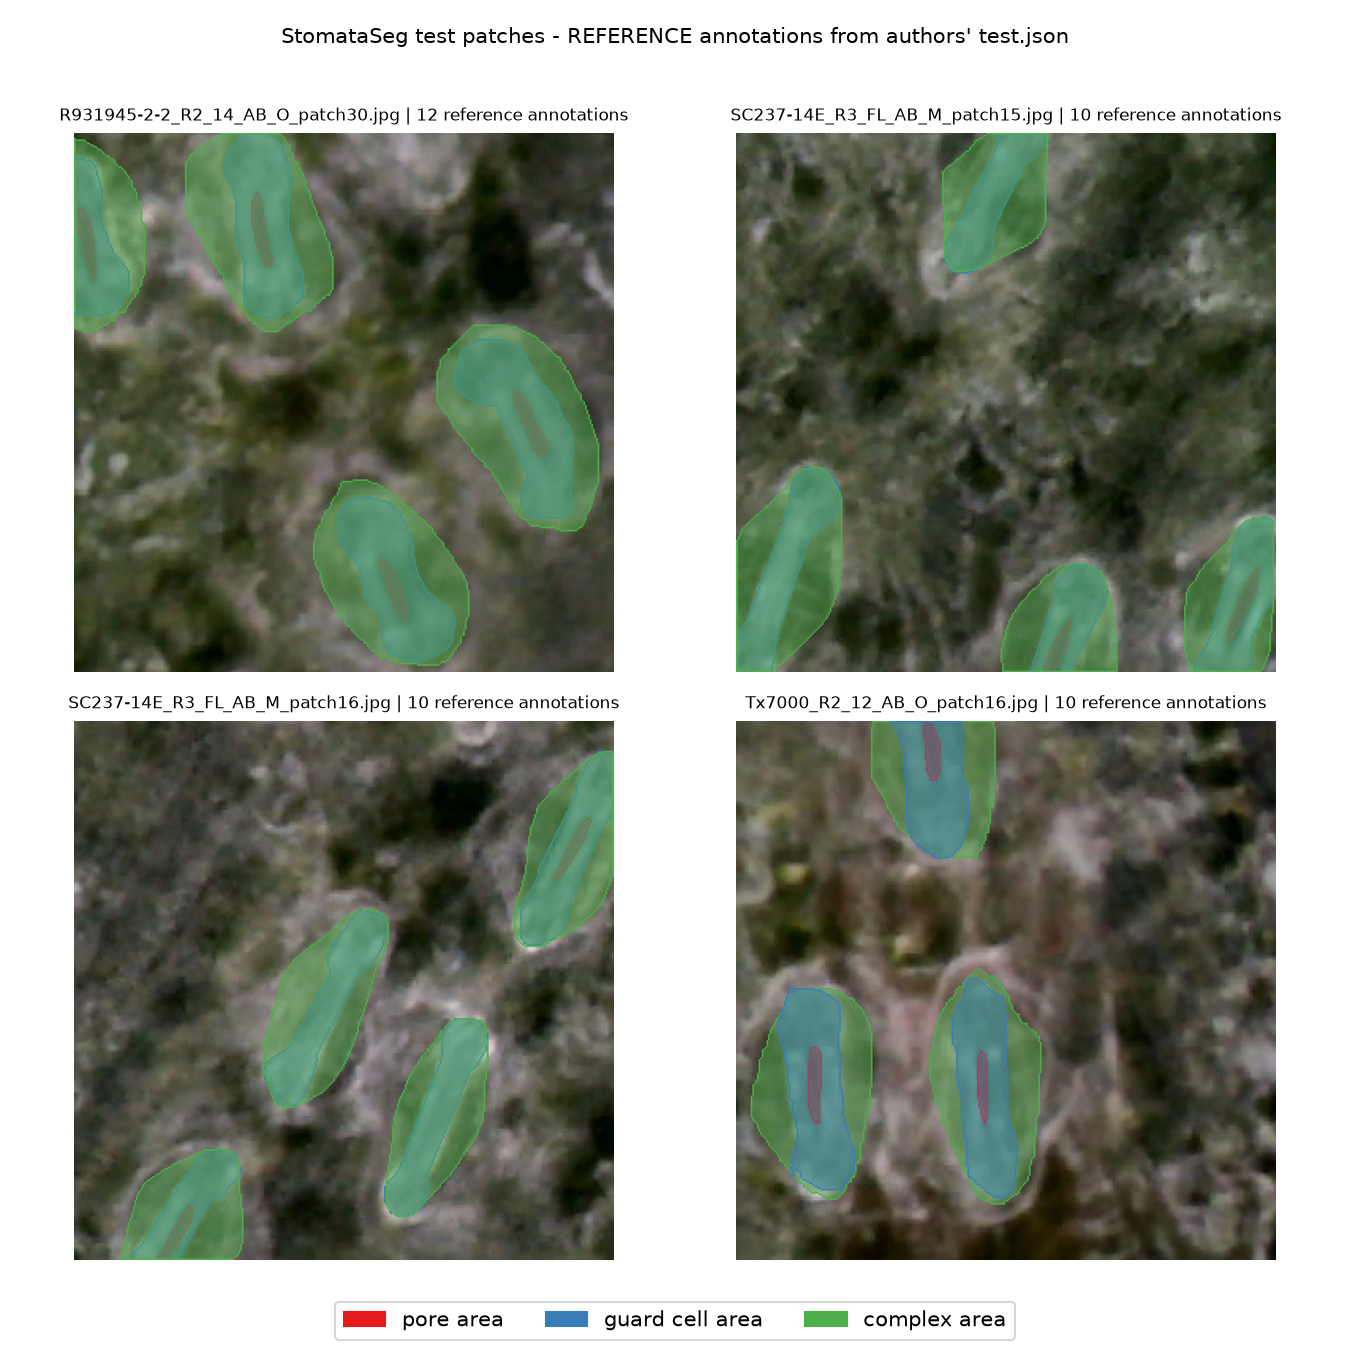

In [ ]:
from IPython.display import Image as IPyImage
IPyImage(filename="/content/outputs/gt_preview.png")

## 10. Model predictions on the same test patches

Runs the released retrained model on the same four patches with the authors' inference
settings from the checkpoint's stored config (native 341 px test scale; Soft-NMS) and
overlays the **predicted** masks. Compare with the reference overlay above; per-class AP
is computed over the full test split in the next section.

日本語: 同じ 4 パッチに対し、チェックポイント保存の推論設定（341 px ネイティブ
スケール、Soft-NMS）で**予測**マスクを重ねて表示します。クラス別 AP は次節で
テスト分割全体から計算します。

In [ ]:
run_venv_script("pred_preview", """
import json, pathlib
import numpy as np
import cv2
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import mmpretrain.models  # noqa: registers the ConvNeXt backbone used by the author config
from mmengine.config import Config
from mmdet.apis import init_detector, inference_detector

pathlib.Path("/content/outputs").mkdir(exist_ok=True)

# the checkpoint stores its own training-time config; use it verbatim (test resize 341)
ck = torch.load("/content/weights/retrained_best.pth", map_location="cpu", weights_only=False)
cfg_text = ck["meta"]["cfg"]
assert isinstance(cfg_text, str)
pathlib.Path("/content/author_train_cfg.py").write_text(cfg_text)
cfg = Config.fromfile("/content/author_train_cfg.py")
print("stored experiment:", ck["meta"].get("experiment_name"), "| epoch:", ck["meta"].get("epoch"))

test_root = pathlib.Path("/content/data/stomata_test_raw")
src_json = next(test_root.rglob("test.json"))
data = json.load(open(src_json))
fn0 = data["images"][0]["file_name"]
img_dir = (src_json.parent / fn0).parent
img_prefix = "." if img_dir == src_json.parent else str(img_dir.relative_to(src_json.parent)) + "/"

counts = {}
for a in data["annotations"]:
    counts[a["image_id"]] = counts.get(a["image_id"], 0) + 1
imgs = sorted(data["images"], key=lambda im: (-counts.get(im["id"], 0), im["id"]))[:4]

model = init_detector(cfg, "/content/weights/retrained_best.pth", device="cuda:0")
class_names = model.dataset_meta["classes"]
colors = {"pore area": (228, 26, 28), "guard cell area": (55, 126, 184), "complex area": (77, 175, 74)}

fig, axes = plt.subplots(2, 2, figsize=(9, 9))
for ax, im in zip(axes.ravel(), imgs):
    path = str(src_json.parent / img_prefix / im["file_name"])
    img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
    canvas = img.copy()
    res = inference_detector(model, path)
    pred = res.pred_instances
    n_kept = 0
    for i in range(len(pred.scores)):
        label = class_names[int(pred.labels[i])]
        c = colors.get(label, (200, 200, 200))
        m = pred.masks[i].cpu().numpy().astype(bool)
        if not m.any():
            continue
        layer = canvas.copy()
        layer[m] = c
        canvas = cv2.addWeighted(layer, 0.45, canvas, 0.55, 0)
        cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(canvas, cnts, -1, c, 1)
        n_kept += 1
    ax.imshow(canvas)
    ax.set_title(f"{im['file_name']} | {n_kept} predicted instances", fontsize=8)
    ax.axis("off")
handles = [plt.Rectangle((0, 0), 1, 1, color=tuple(np.array(c) / 255.0)) for c in colors.values()]
fig.legend(handles, list(colors), loc="lower center", ncol=3)
fig.suptitle("StomataSeg test patches - MODEL PREDICTIONS (retrained_best.pth)", fontsize=10)
fig.tight_layout(rect=[0, 0.05, 1, 0.97])
fig.savefig("/content/outputs/pred_preview.png", dpi=150)
print("saved /content/outputs/pred_preview.png")
""")

stored experiment: mask_rcnn_patched_dataset_20251019_092324 | epoch: 25


Loads checkpoint by local backend from path: /content/weights/retrained_best.pth


saved /content/outputs/pred_preview.png


'stored experiment: mask_rcnn_patched_dataset_20251019_092324 | epoch: 25\nLoads checkpoint by local backend from path: /content/weights/retrained_best.pth\nsaved /content/outputs/pred_preview.png\n'

The rendered prediction overlay (saved PNG from the executed script above):
**MODEL PREDICTIONS** from `retrained_best.pth` — not reference annotations.
日本語: 上記は `retrained_best.pth` による**予測**オーバーレイ画像です
（参照アノテーションではありません）。

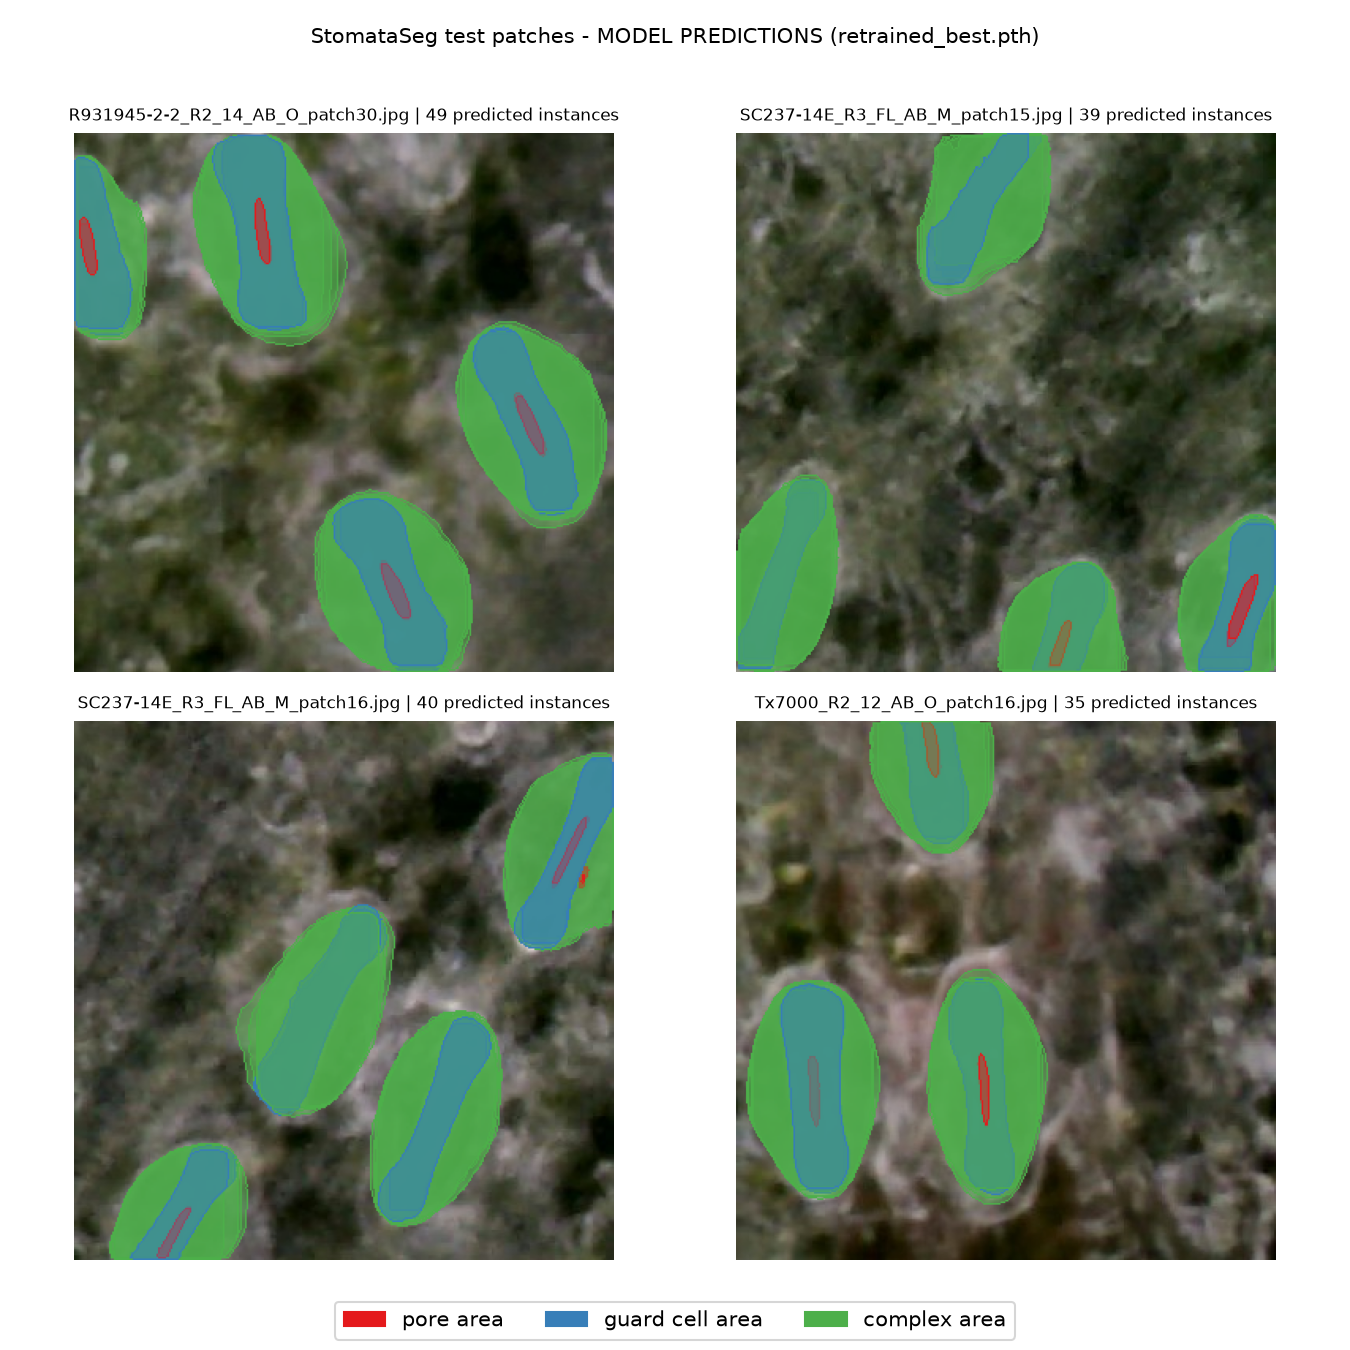

In [ ]:
from IPython.display import Image as IPyImage
IPyImage(filename="/content/outputs/pred_preview.png")

## 11. Full test-split evaluation with the authors' stored config

Builds the evaluation directly from the **configuration stored inside the released
checkpoint** (`meta["cfg"]`, experiment `mask_rcnn_patched_dataset_20251019_092324`) —
the artifact-faithful test path: native 341 px test resize, Soft-NMS, COCO AP on bbox
and segm — over all 1,160 test patches via `mmengine.Runner.test()` (the same path as
the authors' `instance_segmentation/tools/test.py`). The only changes are the data paths
(pointed at the extracted Colab copy). Expected: ≈2 min on T4 with progress markers.

日本語: リリース済みチェックポイントが保持する学習時設定をそのまま使い、
テスト分割 1,160 パッチ全体を評価します（T4 で約 2 分）。変更はデータパスの
指定のみです。

In [ ]:
run_venv_script("full_eval", """
import json, pathlib, time
import torch
import mmpretrain.models  # noqa
from mmengine.config import Config
from mmengine.runner import Runner

ck = torch.load("/content/weights/retrained_best.pth", map_location="cpu", weights_only=False)
cfg_text = ck["meta"]["cfg"]
assert isinstance(cfg_text, str)
pathlib.Path("/content/author_train_cfg.py").write_text(cfg_text)
pcfg = Config.fromfile("/content/author_train_cfg.py")
print("stored experiment:", ck["meta"].get("experiment_name"), "| epoch:", ck["meta"].get("epoch"))

test_root = pathlib.Path("/content/data/stomata_test_raw")
src_json = next(test_root.rglob("test.json"))
data = json.load(open(src_json))
fn0 = data["images"][0]["file_name"]
img_dir = (src_json.parent / fn0).parent
img_prefix = "." if img_dir == src_json.parent else str(img_dir.relative_to(src_json.parent)) + "/"
n_img, n_ann = len(data["images"]), len(data["annotations"])
print(f"test split: {n_img} images, {n_ann} annotations")

pcfg.data_root = str(src_json.parent) + "/"
pcfg.test_dataloader.dataset.data_root = str(src_json.parent) + "/"
pcfg.test_dataloader.dataset.ann_file = "test.json"
pcfg.test_dataloader.dataset.data_prefix = dict(img=img_prefix)
pcfg.test_evaluator.ann_file = str(src_json)
pcfg.work_dir = "/content/work_dirs/eval"
pcfg.load_from = "/content/weights/retrained_best.pth"

runner = Runner.from_cfg(pcfg)
t0 = time.time()
metrics = runner.test()
elapsed = time.time() - t0
print(f"EVALUATION WALL TIME: {elapsed:.0f} s for {n_img} images on {torch.cuda.get_device_name(0)}")
pathlib.Path("/content/outputs").mkdir(exist_ok=True)
metrics["wall_time_s"] = elapsed
metrics["n_images"] = n_img
json.dump(metrics, open("/content/outputs/metrics.json", "w"), indent=1)
print("saved /content/outputs/metrics.json")
""")

stored experiment: mask_rcnn_patched_dataset_20251019_092324 | epoch: 25


test split: 1160 images, 3648 annotations


10/26 08:04:26 - mmengine - INFO - 


------------------------------------------------------------


System environment:


...

10/26 08:06:03 - mmengine - INFO - segm_mAP_copypaste: 0.492 0.888 0.499 0.127 0.504 0.650


10/26 08:06:03 - mmengine - INFO - Epoch(test) [145/145]    coco/pore area_precision: 0.3910  coco/guard cell area_precision: 0.5030  coco/complex area_precision: 0.5830  coco/bbox_mAP: 0.5350  coco/bbox_mAP_50: 0.8950  coco/bbox_mAP_75: 0.5900  coco/bbox_mAP_s: 0.1540  coco/bbox_mAP_m: 0.5410  coco/bbox_mAP_l: 0.6720  coco/segm_mAP: 0.4920  coco/segm_mAP_50: 0.8880  coco/segm_mAP_75: 0.4990  coco/segm_mAP_s: 0.1270  coco/segm_mAP_m: 0.5040  coco/segm_mAP_l: 0.6500  data_time: 0.0418  time: 0.5903


EVALUATION WALL TIME: 93 s for 1160 images on Tesla T4


saved /content/outputs/metrics.json


"stored experiment: mask_rcnn_patched_dataset_20251019_092324 | epoch: 25\ntest split: 1160 images, 3648 annotations\n10/26 08:04:26 - mmengine - INFO - \n------------------------------------------------------------\nSystem environment:\n    sys.platform: linux\n    Python: 3.11.17 (main, Oct 14 2026, 01:05:33) [Clang 23.1.3 ]\n    CUDA available: True\n    MUSA available: False\n    numpy_random_seed: 1841195591\n    GPU 0: Tesla T4\n    CUDA_HOME: /usr/local/cuda\n    NVCC: Cuda compilation tools, release 13.0, V13.0.88\n    GCC: cc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0\n    PyTorch: 2.1.0+cu121\n    PyTorch compiling details: PyTorch built with:\n  - GCC 9.3\n  - C++ Version: 201703\n  - Intel(R) oneAPI Math Kernel Library Version 2022.2-Product Build 20220804 for Intel(R) 64 architecture applications\n  - Intel(R) MKL-DNN v3.1.1 (Git Hash 64f6bcbcbab628e96f33a62c3e975f8535a7bde4)\n  - OpenMP 201511 (a.k.a. OpenMP 4.5)\n  - LAPACK is enabled (usually provided by MKL)\n  - NNPACK i

## 12. Results: reproduced metrics vs paper Table 4

Loads the saved metrics and compares them with Table 4 of the paper (retrained model,
**mask AP**: Overall 49.20/88.80; pore 39.10/82.90; guard cell 50.30/90.60;
complex 58.30/93.10). The metric keys carry a `coco/` prefix; the per-class values come
from CocoMetric's `{class}_precision` entries (the last-computed metric family, segm —
the paper's metric); reproduced values are shown in % like the paper. A CSV export is written to
`/content/outputs/stomataseg_eval_results.csv`.

日本語: 保存したメトリクスを読み込み、論文 Table 4（再学習後、mask AP）と比較します。
クラス別値は CocoMetric の `{class}_precision`（最後に計算された segm 由素）から取得し、
CSV は `/content/outputs/stomataseg_eval_results.csv` に保存します。

In [ ]:
import json, pandas as pd

m = json.load(open("/content/outputs/metrics.json"))
def g(key):
    return float(m.get(key, m.get("coco/" + key, float("nan"))))
def per_class(cls):  # CocoMetric classwise per-class AP (segm; matches Table 4)
    return float(m.get(f"coco/{cls}_precision", m.get(f"{cls}_precision", float("nan"))))

paper = {"Overall": (49.20, 88.80), "pore area": (39.10, 82.90),
         "guard cell area": (50.30, 90.60), "complex area": (58.30, 93.10)}
rows = []
for cls, (pap, pap50) in paper.items():
    if cls == "Overall":
        rep_ap, rep_ap50 = 100 * g("segm_mAP"), 100 * g("segm_mAP_50")
        rep_bbox_ap, rep_bbox_ap50 = 100 * g("bbox_mAP"), 100 * g("bbox_mAP_50")
    else:
        rep_ap, rep_ap50 = 100 * per_class(cls), float("nan")
        rep_bbox_ap, rep_bbox_ap50 = float("nan"), float("nan")
    rows.append({"class": cls, "paper Table4 mask AP": pap, "paper Table4 mask AP50": pap50,
                 "reproduced mask AP": rep_ap, "reproduced mask AP50": rep_ap50,
                 "reproduced bbox AP": rep_bbox_ap, "reproduced bbox AP50": rep_bbox_ap50})
df = pd.DataFrame(rows).round(2)
display(df)
df.to_csv("/content/outputs/stomataseg_eval_results.csv", index=False)
print("wall time:", round(m.get("wall_time_s", 0)), "s |", m.get("n_images"), "test images")
print("saved /content/outputs/stomataseg_eval_results.csv")

,class,paper Table4 mask AP,paper Table4 mask AP50,reproduced mask AP,reproduced mask AP50,reproduced bbox AP,reproduced bbox AP50
0,Overall,49.2,88.8,49.2,88.8,53.5,89.5
1,pore area,39.1,82.9,39.1,NaN,NaN,NaN
2,guard cell area,50.3,90.6,50.3,NaN,NaN,NaN
3,complex area,58.3,93.1,58.3,NaN,NaN,NaN


wall time: 93 s | 1160 test images
saved /content/outputs/stomataseg_eval_results.csv


## 13. Comparison graph: paper Table 4 vs this reproduction

Bar chart of per-class **mask AP50** — paper Table 4 against this reproduction (overall
values in the table above). This is a comparison visualization created for this notebook,
not an author figure.

日本語: 論文 Table 4 と再現値の mask AP50 をクラス別に比較する棒グラフです。
このノートブック用に作成した比較図であり、著者の図ではありません。

In [ ]:
import pathlib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = pd.read_csv("/content/outputs/stomataseg_eval_results.csv")
df = df[df["class"] != "Overall"].copy()
classes = df["class"].tolist()
x = np.arange(len(classes)); w = 0.35
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - w/2, df["paper Table4 mask AP"], w, label="paper Table 4 mask AP", color="0.6")
ax.bar(x + w/2, df["reproduced mask AP"], w, label="reproduced mask AP", color="#4daf4a")
ax.set_xticks(x); ax.set_xticklabels(classes)
ax.set_ylabel("mask AP (%)"); ax.set_ylim(0, 100)
ax.set_title("StomataSeg retrained model, test split: paper vs reproduction")
ax.legend()
fig.tight_layout()
pathlib.Path("/content/outputs").mkdir(exist_ok=True)
fig.savefig("/content/outputs/table4_comparison.png", dpi=150)
print("saved /content/outputs/table4_comparison.png")

saved /content/outputs/table4_comparison.png


The rendered comparison graph (saved PNG from the executed script above):
paper Table 4 mask AP50 vs reproduced mask AP50 per class.
日本語: 論文 Table 4 と再現値の mask AP50 比較グラフです。

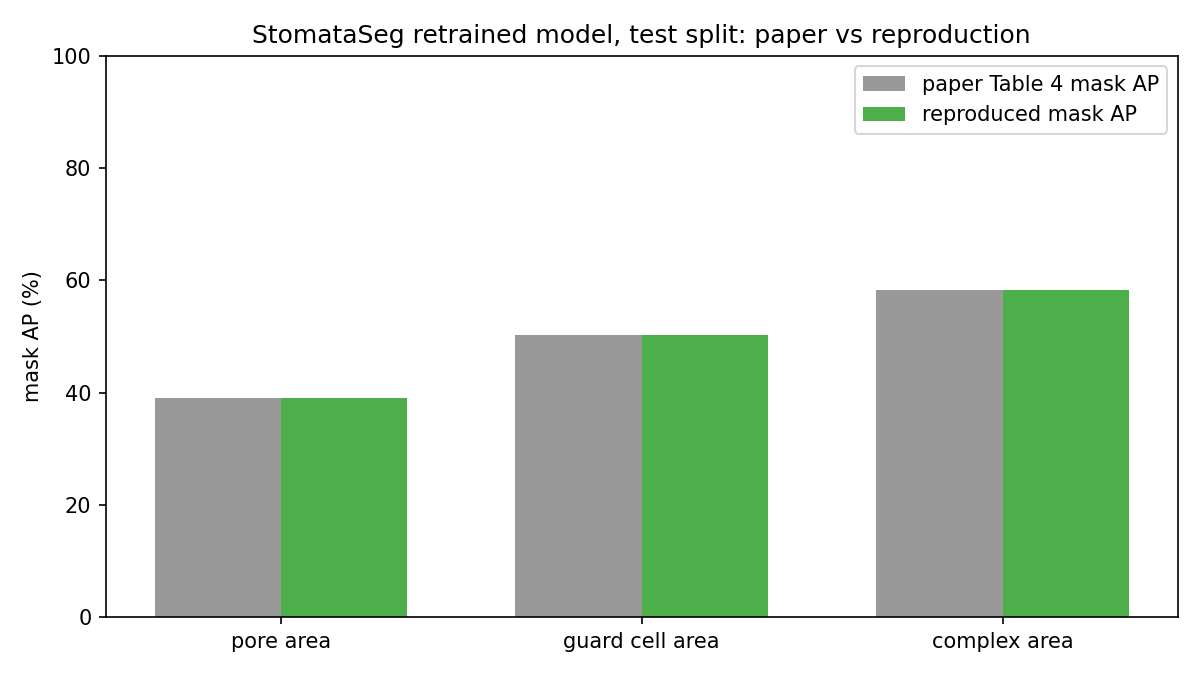

In [ ]:
from IPython.display import Image as IPyImage
IPyImage(filename="/content/outputs/table4_comparison.png")

## 14. Interpretation, scope and validation record

- **What was validated:** the authors' released retrained checkpoint (`retrained_best.pth`,
  release v1.0.0) was evaluated on the **full official test split** (1,160 patches) using
  the evaluation configuration stored inside the checkpoint itself (native 341 px test
  scale, Soft-NMS) — the same code path as their `instance_segmentation/tools/test.py`.
  Reference annotations and predictions were visualized on four annotation-rich patches
  (deterministic selection).
- **Agreement with the paper:** Table 4's "AP" is mask (segm) AP; on this run the
  reproduced overall and per-class mask AP/AP50 match Table 4 (49.20/88.80 overall) to
  within rounding (~0.1). The bounding-box AP is additionally reported in the table above
  for completeness. A large deviation on reruns would indicate a provenance or runtime
  problem and should be reported rather than tuned away.
- **Documented discrepancy:** the repo's standalone `mask_rcnn_convnext_v2_b_stomata.py`
  config resizes test patches to 800 px and yields far lower AP (~13 bbox AP on this
  split); the checkpoint's stored config (patch-based experiment, 341 px) is the correct
  evaluation route for the released weights. The checkpoint's stored experiment name is
  `mask_rcnn_patched_dataset_20251019_092324`.
- **Not reproduced:** training, the seed-model baseline, semantic segmentation baselines,
  the SAM2.1 zero-shot baseline, and pseudo-label generation. A single-run evaluation does
  not re-verify the paper's full benchmark.
- **Dataset license note:** the paper states CC BY-NC-ND 4.0 for the dataset while the
  Zenodo record metadata reports cc-by-4.0; reuse beyond this verification should check
  the current terms.

日本語: 検証済み内容は、著者公開チェックポイントをチェックポイント保存の評価設定のまま
公式テスト分割全体（1,160 パッチ）で評価したことで、論文 Table 4（mask AP）と
丸め誤差以内で一致しました。学習や seed モデル比較、意味論セグメンテーション、
SAM2.1、擬似ラベル生成は対象外です。リポジトリの単体設定（800 px リサイズ）では
低い AP になる点に注意してください。ライセンス表記の不一致（論文: CC BY-NC-ND 4.0 /
Zenodo: CC BY 4.0）にも注意してください。

### References
1. *StomataSeg: Semi-Supervised Instance Segmentation for Sorghum Stomatal Components.*
   Computers and Electronics in Agriculture (2026), DOI 10.1016/j.compag.2026.112442.
   Preprint: arXiv:2602.00703.
2. Code: https://github.com/Davidhzt/StomataSeg_full (commit `6ba8a661`)
3. Weights: https://github.com/Davidhzt/StomataSeg_full/releases/tag/v1.0.0
4. Data: https://zenodo.org/records/18216859
5. MMDetection: https://github.com/open-mmlab/mmdetection (v3.3.0 base configs)